# 02 · Cost Baseline — What does the current schedule cost?

**Project:** Industrial Load Shifting · **Author:** Swaroop Jadhav

### Purpose
Every saving needs a reference point. Before optimising anything, we calculate what the machines'
**current** schedule would cost at today's 15-minute prices. That number is the **baseline**.
We also calculate an **upper bound**: the most that shifting within the same day could ever save.
If even the upper bound is small, an optimisation project is not worth it — that is a key business check.

### Business questions
1. Which machines use the most energy, and when does the workshop run?
2. What would one year of electricity cost at 15-minute day-ahead prices?
3. Do the machines pay more or less than the market average because of *when* they run?
4. How much could shifting within the day save **at most**?

**Data:** KIT SPARK, TEC workshop, 11 machines, 2024 (5-second readings → 15 minutes).
**Prerequisites:** `python src/download_prices.py` and `python src/load_spark_data.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent / "src"))
import config
import cost

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#898781", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "lines.linewidth": 2, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 12,
})
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
LABELS = config.SPARK_MACHINES          # e.g. TEC_Chiron800 -> "Chiron 800 (5-axis mill)"

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight")

def euro(x):
    return f"€{x:,.0f}"

---
## Part A · The workshop machines

### A1. Overview

In [2]:
loads = pd.read_csv(config.SPARK_LOAD_FILE, parse_dates=["timestamp_utc"])
loads["timestamp_local"] = loads["timestamp_utc"].dt.tz_convert(config.LOCAL_TZ)
loads["label"] = loads["machine"].map(LABELS).fillna(loads["machine"])

overview = loads.groupby("label").agg(
    energy_mwh=("energy_kwh", lambda s: s.sum() / 1000),
    avg_kw=("avg_kw", "mean"),
    peak_kw=("avg_kw", "max"),
    coverage_pct=("coverage", lambda s: 100 * s.mean()),
).sort_values("energy_mwh", ascending=False)
overview["share_%"] = 100 * overview["energy_mwh"] / overview["energy_mwh"].sum()
print(f"Total: {overview['energy_mwh'].sum():,.1f} MWh in 2024 from {len(overview)} machines")
overview.round(1)

Total: 95.9 MWh in 2024 from 11 machines


,energy_mwh,avg_kw,peak_kw,coverage_pct,share_%
label,,,,,
DNG 50 evo (mill),40.1,4.8,12.6,95.1,41.9
JWA 24 (liquid cooler),18.2,2.2,11.9,95.1,19.0
MV 2400 R (wire EDM),11.0,1.3,12.5,95.1,11.4
CF ST 161 (water chiller),8.8,1.1,7.9,95.1,9.2
DMU 125 (5-axis mill),6.0,0.7,16.2,95.1,6.3
Chiron 800 (5-axis mill),5.7,0.7,7.8,95.1,6.0
CTX 800 TC (lathe-mill),2.5,0.3,5.2,95.1,2.7
E110 (lathe),2.3,0.3,9.9,95.1,2.4
E30 D2 (lathe),0.6,0.1,1.6,95.1,0.6


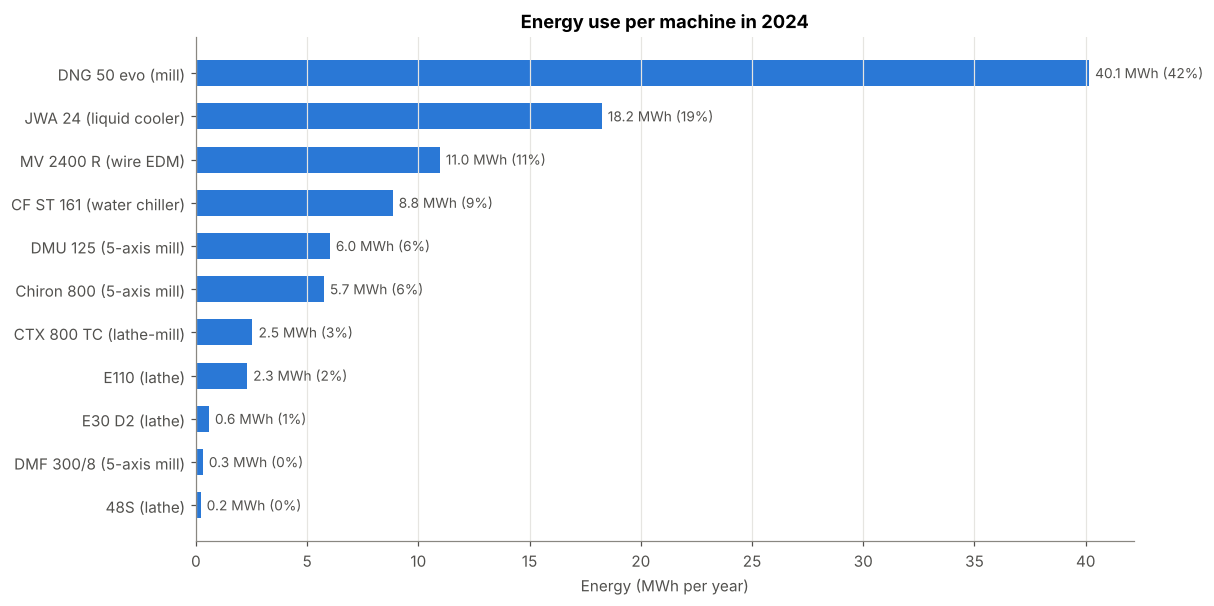

In [3]:
fig, ax = plt.subplots(figsize=(11, 0.45 * len(overview) + 1))
o = overview.sort_values("energy_mwh")
ax.barh(o.index, o["energy_mwh"], color=COLORS[0], height=0.6)
for y, (v, s) in enumerate(zip(o["energy_mwh"], o["share_%"])):
    ax.annotate(f"{v:,.1f} MWh ({s:.0f}%)", xy=(v, y), xytext=(4, 0), textcoords="offset points",
                va="center", color="#52514e", fontsize=9)
ax.set(title="Energy use per machine in 2024", xlabel="Energy (MWh per year)")
ax.grid(axis="y", visible=False)
save(fig, "W2_A1_energy_per_machine")
plt.show()

**Interpretation**

Energy use is very concentrated. The DNG 50 evo mill alone used 40.1 MWh in 2024, which is 42% of the whole workshop, and the JWA 24 liquid cooler adds another 19%. Together with the wire EDM (11%) and the CF ST 161 water chiller (9%), four machines account for about 82% of the energy.

The other seven machines are small. Three of them (48S, DMF 300/8, E30 D2) are each below 1%, so they are not really relevant for the cost analysis. I was surprised that the biggest consumer is not one of the 5-axis mills, which have the highest peak power (DMU 125: 16.2 kW), but the DNG 50 evo, because it uses a lot of energy all the time and not only when it is producing.

### A2. When does the workshop run?
Average total power of all machines for each weekday and hour (2024). Darker = more power.

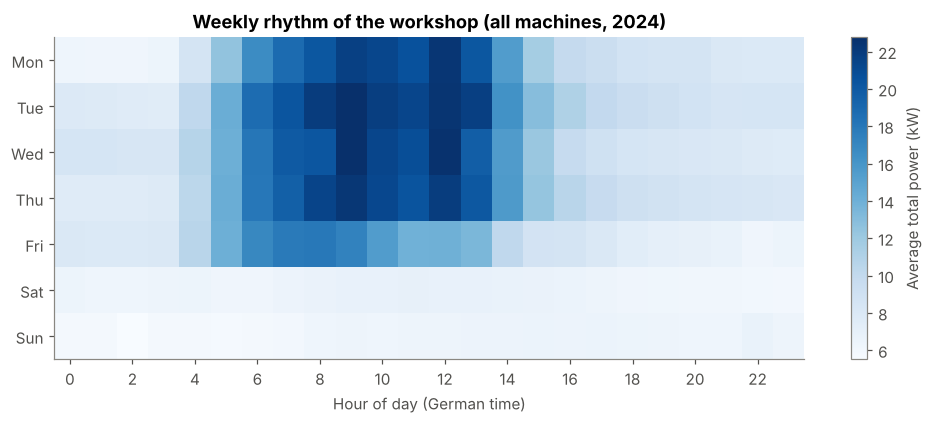

In [4]:
total = loads.groupby("timestamp_local")["avg_kw"].sum().to_frame("kw")
total["weekday"] = total.index.day_of_week
total["hour"] = total.index.hour
rhythm = total.pivot_table(index="weekday", columns="hour", values="kw", aggfunc="mean")

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(rhythm.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(7)); ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.grid(False)
fig.colorbar(im, ax=ax).set_label("Average total power (kW)")
ax.set(title="Weekly rhythm of the workshop (all machines, 2024)", xlabel="Hour of day (German time)")
save(fig, "W2_A2_weekly_rhythm")
plt.show()

**Interpretation**

The workshop works Monday to Thursday from about 05:00 to 15:00, with the highest load (around 22 kW) between 09:00 and 12:00. Friday is shorter and lower, it already drops after about 13:00. After 15:00 the load goes down slowly, and there is no real evening or night shift.

What stands out is that the load never goes to zero. At night and on weekends there is still a base load of about 6 to 8 kW. Looking at the machines at night (02:00 to 04:00), most of it comes from the DNG 50 evo (about 4.2 kW) and the JWA 24 liquid cooler (about 1.6 kW), plus smaller parts from the CF ST 161 chiller and the wire EDM. So some machines seem to stay switched on even when nobody is working.

---
## Part B · Replaying 2024 machine loads against today's prices

The machine data is from **2024**, the prices from **Oct 2025 – Sep 2026**. We match each price
quarter-hour with the machine load from the **same week of the year, same weekday and same time of day**
(assumption A5). Example: *Tuesday of week 10, 09:15* in 2026 uses the load of *Tuesday of week 10, 09:15* in 2024.

This keeps the weekly rhythm and the seasons. Limitation: public holidays fall on different days in different years.

**Sanity check:** the yearly energy must stay (almost) the same after matching. Differences come from
2024 having 366 days and the price year 365, and from filling the measurement gaps (A6), which adds energy
for periods the logger missed.

In [5]:
prices = pd.read_csv(config.PRICES_RAW_FILE, parse_dates=["timestamp_utc"])
aligned = cost.align_load_to_prices(loads, prices)
machines = aligned.attrs["machines"]

check = pd.DataFrame({
    "energy_2024_mwh": loads.groupby("machine")["energy_kwh"].sum() / 1000,
    "energy_replayed_mwh": aligned[machines].sum() / 1000,
})
check["difference_%"] = 100 * (check["energy_replayed_mwh"] / check["energy_2024_mwh"] - 1)
print(f"Machine data gaps filled with the typical weekday/time load (A6): {aligned.attrs['gap_filled_share']:.1%}")
print(f"Price quarter-hours without any matching machine data: {aligned.attrs['unmatched_share']:.2%}")
check.rename(index=LABELS).round(2)

Machine data gaps filled with the typical weekday/time load (A6): 4.8%
Price quarter-hours without any matching machine data: 0.00%


,energy_2024_mwh,energy_replayed_mwh,difference_%
48S (lathe),0.21,0.22,4.52
CF ST 161 (water chiller),8.84,9.38,6.09
CTX 800 TC (lathe-mill),2.54,2.63,3.58
Chiron 800 (5-axis mill),5.75,5.98,4.06
DMF 300/8 (5-axis mill),0.31,0.32,4.72
DMU 125 (5-axis mill),6.02,6.25,3.86
DNG 50 evo (mill),40.15,42.15,4.98
E110 (lathe),2.30,2.40,4.23
E30 D2 (lathe),0.58,0.61,4.46
JWA 24 (liquid cooler),18.24,19.07,4.53


---
## Part C · The baseline: what does the current schedule cost?

⚠️ **Wholesale part only** (assumptions A1, A2): grid fees, taxes and levies come on top, but they are
the same at every hour, so they do not change *where* savings come from.

**Price paid vs. market average** is the key indicator: if a machine's energy-weighted price is *below*
the simple market average, it already runs at cheaper-than-average times — and the other way round.

In [6]:
baseline = cost.baseline_cost(aligned).rename(index=LABELS)
market_avg = aligned["price_eur_mwh"].mean()
baseline["vs_market_%"] = 100 * (baseline["price_paid_eur_mwh"] / market_avg - 1)

tot = baseline.loc["TOTAL"]
print(f"Baseline electricity cost (wholesale): {euro(tot['cost_eur'])} per year for {tot['energy_mwh']:,.1f} MWh")
print(f"Price paid: {tot['price_paid_eur_mwh']:.1f} €/MWh  vs. market average {market_avg:.1f} €/MWh "
      f"({tot['vs_market_%']:+.1f}%)")
baseline.round(1)

Baseline electricity cost (wholesale): €10,573 per year for 100.4 MWh
Price paid: 105.3 €/MWh  vs. market average 104.0 €/MWh (+1.2%)


,energy_mwh,cost_eur,price_paid_eur_mwh,vs_market_%
DNG 50 evo (mill),42.1,4405.4,104.5,0.5
JWA 24 (liquid cooler),19.1,2013.1,105.6,1.5
MV 2400 R (wire EDM),11.4,1254.0,109.6,5.3
CF ST 161 (water chiller),9.4,939.3,100.1,-3.8
DMU 125 (5-axis mill),6.2,668.9,107.1,2.9
Chiron 800 (5-axis mill),6.0,649.4,108.6,4.3
CTX 800 TC (lathe-mill),2.6,291.4,110.7,6.4
E110 (lathe),2.4,227.9,95.1,-8.6
E30 D2 (lathe),0.6,64.9,106.7,2.5
DMF 300/8 (5-axis mill),0.3,34.2,106.2,2.0


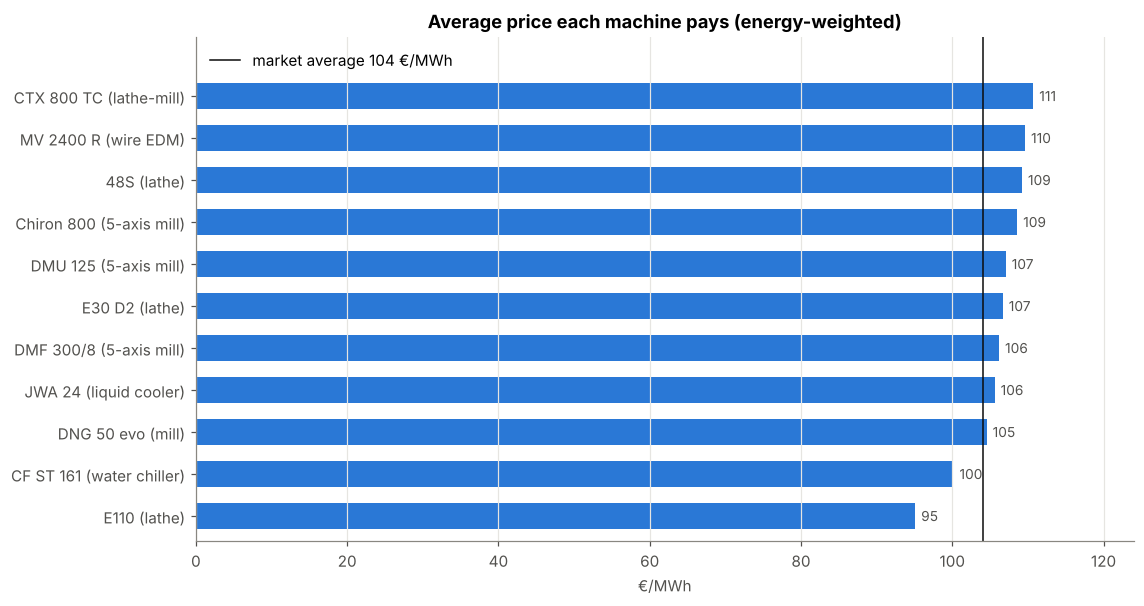

In [7]:
b = baseline.drop(index="TOTAL").sort_values("price_paid_eur_mwh")
fig, ax = plt.subplots(figsize=(11, 0.45 * len(b) + 1))
ax.barh(b.index, b["price_paid_eur_mwh"], color=COLORS[0], height=0.6)
ax.axvline(market_avg, color="#0b0b0b", linewidth=1, label=f"market average {market_avg:.0f} €/MWh")
for y, v in enumerate(b["price_paid_eur_mwh"]):
    ax.annotate(f"{v:.0f}", xy=(v, y), xytext=(4, 0), textcoords="offset points", va="center",
                color="#52514e", fontsize=9)
ax.set(title="Average price each machine pays (energy-weighted)", xlabel="€/MWh",
       ylim=(-0.6, len(b) + 0.4),                       # free row on top for the legend
       xlim=(0, max(b["price_paid_eur_mwh"].max(), market_avg) * 1.12))
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", visible=False)
save(fig, "W2_C1_price_paid")
plt.show()

**Interpretation**

In total, the workshop pays 105.3 €/MWh, which is 1.2% above the market average of 104.0 €/MWh. So it does not profit from cheap times at the moment, it is roughly at market level or slightly worse.

Most of the production machines pay above average: the CTX 800 TC (+6.4%), the wire EDM (+5.3%) and the Chiron 800 (+4.3%). These machines mainly run in the morning, which is exactly when the morning price peak happens (around 07:00 to 08:00). Only two machines pay less than average: the E110 lathe (−8.6%) and the CF ST 161 chiller (−3.8%). For the chiller this makes sense because it also runs at night and at midday when prices are lower. For the E110 I would guess it runs more around midday, but I would need to check its daily profile to be sure.

### C2. When is the money spent?
Top: how much energy the workshop uses in each hour of the day. Bottom: the average price in that hour.
Hours where both are high are where load shifting can save the most.

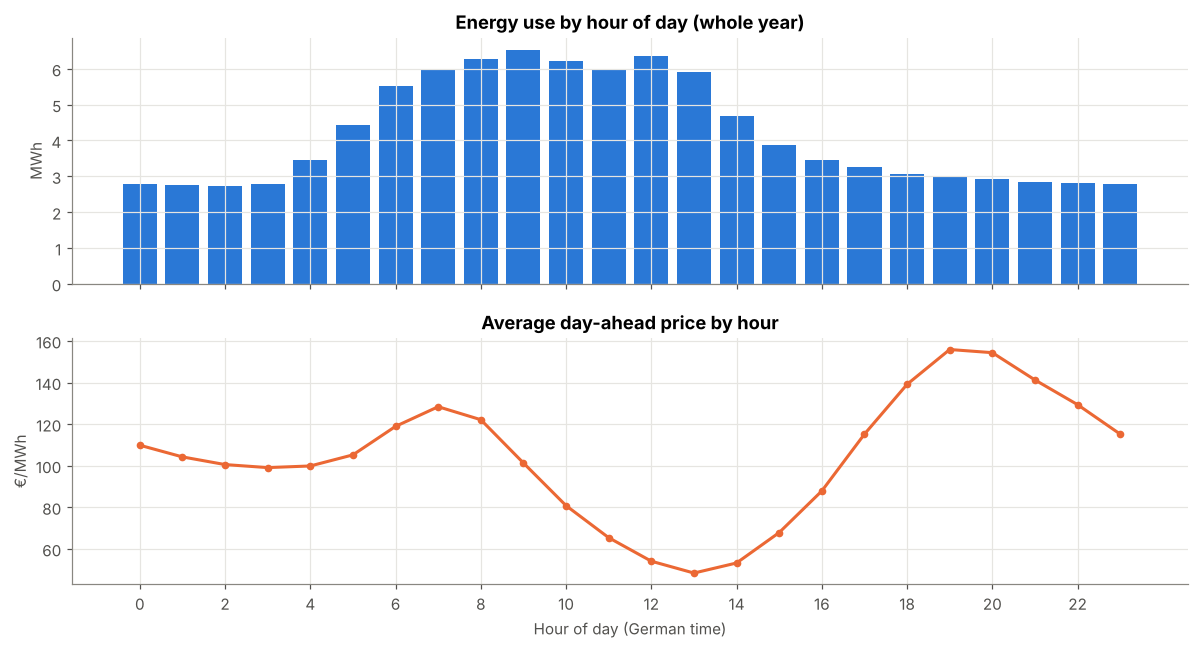

Most expensive hours for the workshop: 07:00 (€832), 08:00 (€830), 09:00 (€728)


In [8]:
aligned["hour"] = aligned["timestamp_local"].dt.hour
aligned["total_kwh"] = aligned[machines].sum(axis=1)
aligned["total_cost_eur"] = aligned["total_kwh"] / 1000 * aligned["price_eur_mwh"]
by_hour = aligned.groupby("hour").agg(energy_mwh=("total_kwh", lambda s: s.sum() / 1000),
                                      price=("price_eur_mwh", "mean"),
                                      cost_eur=("total_cost_eur", "sum"))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.bar(by_hour.index, by_hour["energy_mwh"], color=COLORS[0], width=0.8)
ax1.set(title="Energy use by hour of day (whole year)", ylabel="MWh")
ax2.plot(by_hour.index, by_hour["price"], color=COLORS[1], marker="o", markersize=4)
ax2.set(title="Average day-ahead price by hour", ylabel="€/MWh", xlabel="Hour of day (German time)",
        xticks=range(0, 24, 2))
fig.tight_layout()
save(fig, "W2_C2_energy_vs_price_by_hour")
plt.show()

top = by_hour.sort_values("cost_eur", ascending=False).head(3)
print("Most expensive hours for the workshop:",
      ", ".join(f"{h:02d}:00 ({euro(c)})" for h, c in top["cost_eur"].items()))

**Interpretation**

The most expensive hours for the workshop are 07:00 (€832 per year), 08:00 (€830) and 09:00 (€728). This is because the busy hours start exactly when the morning price peak happens (around 120 to 130 €/MWh at 07:00 to 08:00).

The good news is that the workshop does not run in the evening, when prices are highest (around 155 €/MWh at 19:00 to 20:00). It only has standby load then. The bad news is that it stops working at around 15:00, just after the cheapest hours of the day (the price minimum is around 13:00 with less than 50 €/MWh). So the shift is a bit "too early": starting later and using more of the midday dip would make the same work cheaper.

### C3. Cost through the year

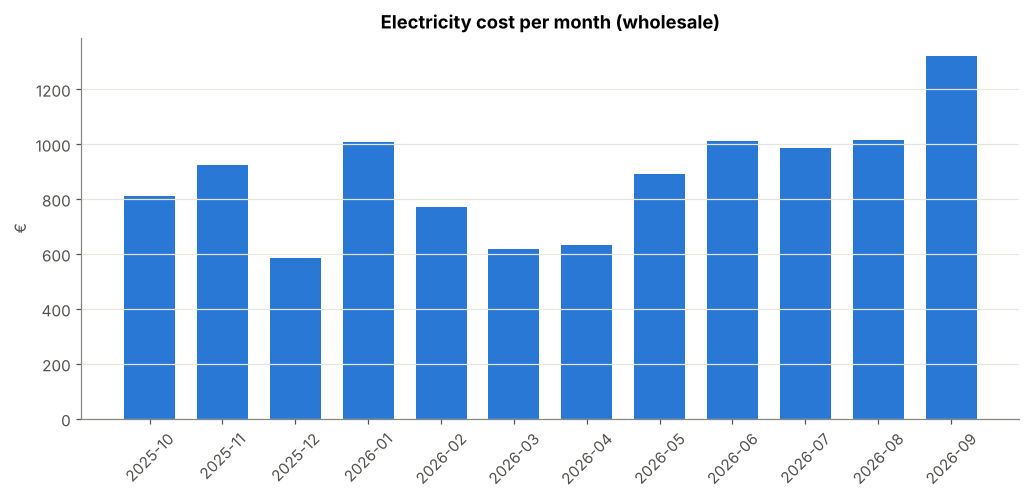

,cost_eur,energy_mwh,price_paid
month,,,
2025-10,810.2,9.2,88.1
2025-11,924.2,8.5,108.9
2025-12,585.4,6.0,97.9
2026-01,1007.9,8.6,116.9
2026-02,770.5,7.6,101.5
2026-03,616.7,6.7,92.0
2026-04,632.3,8.1,78.2
2026-05,891.9,9.2,96.9
2026-06,1009.8,9.5,106.1


In [9]:
aligned["month"] = aligned["timestamp_local"].dt.strftime("%Y-%m")
monthly = aligned.groupby("month").agg(cost_eur=("total_cost_eur", "sum"),
                                       energy_mwh=("total_kwh", lambda s: s.sum() / 1000))
monthly["price_paid"] = monthly["cost_eur"] / monthly["energy_mwh"]

fig, ax = plt.subplots()
ax.bar(monthly.index, monthly["cost_eur"], color=COLORS[0], width=0.7)
ax.set(title="Electricity cost per month (wholesale)", ylabel="€")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
save(fig, "W2_C3_monthly_cost")
plt.show()
monthly.round(1)

**Interpretation**

The most expensive month is September 2026 with €1,322, followed by August (€1,015), June (€1,010) and January (€1,008). The cheapest months are December 2025 (€585), March (€617) and April (€632).

When I compare the two columns, the energy per month is quite stable (between 6 and 9.6 MWh), but the price paid varies a lot, from 78 €/MWh in April to 147 €/MWh in September. So most of the difference between months comes from the prices, not from the workshop using more energy. December is the exception: it is cheap mainly because the workshop used less energy (6.0 MWh), probably because of the Christmas holidays. April is cheap because of the strong solar midday dip in spring that I already saw in notebook 01.

---
## Part D · Two different levers: standby and shifting

A machine's energy has two parts:
- **Standby load** — what it draws even when the workshop is closed (weekends, 00:00–05:00): controls, hydraulics,
  coolant pumps, cooling. This **cannot be shifted**, only **switched off** → an *energy-efficiency* measure.
- **Production load** — everything above standby. Only this part can be **moved** to cheaper hours → *load shifting*.

### D1. How much energy is standby?

In [10]:
bound = cost.savings_upper_bound(aligned).rename(index=LABELS)
t = bound.loc["TOTAL"]
standby_share = 100 * t["standby_mwh"] / (t["standby_mwh"] + t["production_mwh"])
print(f"Standby: {t['standby_mwh']:.1f} MWh = {standby_share:.0f}% of all energy, costing {euro(t['standby_cost_eur'])} per year")
print(f"Production: {t['production_mwh']:.1f} MWh, costing {euro(t['production_cost_eur'])} per year")
cols = ["standby_kw", "standby_mwh", "standby_cost_eur", "production_mwh", "production_cost_eur"]
pd.concat([bound.drop(index="TOTAL").sort_values("standby_cost_eur", ascending=False), bound.loc[["TOTAL"]]])[cols].round(1)

Standby: 48.3 MWh = 48% of all energy, costing €5,072 per year
Production: 52.2 MWh, costing €5,500 per year


,standby_kw,standby_mwh,standby_cost_eur,production_mwh,production_cost_eur
DNG 50 evo (mill),4.1,35.6,3721.4,6.5,684.0
JWA 24 (liquid cooler),2.1,12.0,1278.6,7.1,734.5
CF ST 161 (water chiller),0.1,0.7,72.1,8.7,867.2
DMU 125 (5-axis mill),0.0,0.0,0.0,6.2,668.9
MV 2400 R (wire EDM),0.0,0.0,0.0,11.4,1254.0
Chiron 800 (5-axis mill),0.0,0.0,0.0,6.0,649.4
E110 (lathe),0.0,0.0,0.0,2.4,227.9
CTX 800 TC (lathe-mill),0.0,0.0,0.0,2.6,291.4
E30 D2 (lathe),0.0,0.0,0.0,0.6,64.9
DMF 300/8 (5-axis mill),0.0,0.0,0.0,0.3,34.2


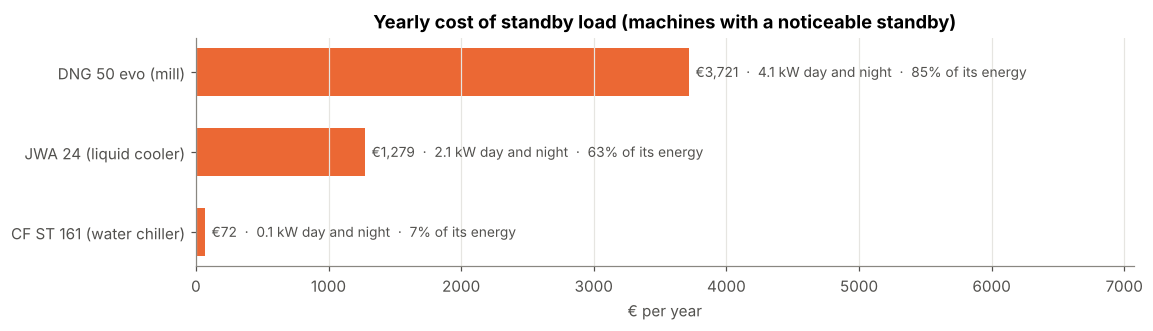

In [11]:
sb = bound.drop(index="TOTAL")
sb = sb[sb["standby_mwh"] > 0.05].sort_values("standby_cost_eur")
fig, ax = plt.subplots(figsize=(11, 0.5 * len(sb) + 1.2))
ax.barh(sb.index, sb["standby_cost_eur"], color=COLORS[1], height=0.6)
for y, (c, kw, share) in enumerate(zip(sb["standby_cost_eur"], sb["standby_kw"],
                                        100 * sb["standby_mwh"] / (sb["standby_mwh"] + sb["production_mwh"]))):
    ax.annotate(f"{euro(c)}  ·  {kw:.1f} kW day and night  ·  {share:.0f}% of its energy", xy=(c, y),
                xytext=(4, 0), textcoords="offset points", va="center", color="#52514e", fontsize=9)
ax.set(title="Yearly cost of standby load (machines with a noticeable standby)", xlabel="€ per year",
       xlim=(0, sb["standby_cost_eur"].max() * 1.9))
ax.grid(axis="y", visible=False)
save(fig, "W2_D1_standby_cost")
plt.show()

**Interpretation**

Almost half of all the energy is standby: 48.3 MWh, which is 48% of the total and costs about €5,070 per year. This comes almost completely from two machines. The DNG 50 evo draws 4.1 kW day and night, which costs €3,721 per year and is 85% of its total energy. The JWA 24 liquid cooler draws 2.1 kW all the time (€1,279 per year, 63% of its energy). The CF ST 161 chiller has only a very small standby (€72).

The obvious idea would be to switch these machines off at night and on weekends, for example with a timer or a fixed shutdown routine at the end of the shift. But before recommending that, I would ask the operators why they stay on. CNC machines are sometimes kept warm on purpose so that they stay dimensionally stable and accurate, and the liquid cooler might be connected to the DNG 50 evo or another machine. If there is a real technical reason, maybe the machine could at least go into a lower standby mode instead of being fully on.

### D2. Upper bound for load shifting (production energy only)

**Rule:** each day, the machine's **production** energy is moved into the cheapest quarter-hours of the **same day**,
preferring the shift window (06:00–22:00), and never above the machine's highest observed load.

This is a **ceiling**, not a plan: it ignores job order, workers, set-up times and process limits.
The realistic saving will be **lower**. If the ceiling is already small, optimisation is not worth it.

In [12]:
print(f"Maximum possible saving from shifting: {euro(t['max_saving_eur'])} per year "
      f"({t['max_saving_%_of_production']:.0f}% of the production energy cost, "
      f"{100 * t['max_saving_eur'] / baseline.loc['TOTAL', 'cost_eur']:.0f}% of the total baseline)")
bound[["production_mwh", "production_cost_eur", "max_saving_eur", "max_saving_%_of_production"]].round(1)

Maximum possible saving from shifting: €2,157 per year (39% of the production energy cost, 20% of the total baseline)


,production_mwh,production_cost_eur,max_saving_eur,max_saving_%_of_production
MV 2400 R (wire EDM),11.4,1254.0,488.8,39.0
JWA 24 (liquid cooler),7.1,734.5,391.6,53.3
DMU 125 (5-axis mill),6.2,668.9,321.3,48.0
Chiron 800 (5-axis mill),6.0,649.4,318.0,49.0
DNG 50 evo (mill),6.5,684.0,226.3,33.1
E110 (lathe),2.4,227.9,131.4,57.7
CF ST 161 (water chiller),8.7,867.2,130.6,15.1
CTX 800 TC (lathe-mill),2.6,291.4,102.4,35.2
E30 D2 (lathe),0.6,64.9,30.9,47.6
DMF 300/8 (5-axis mill),0.3,34.2,9.7,28.4


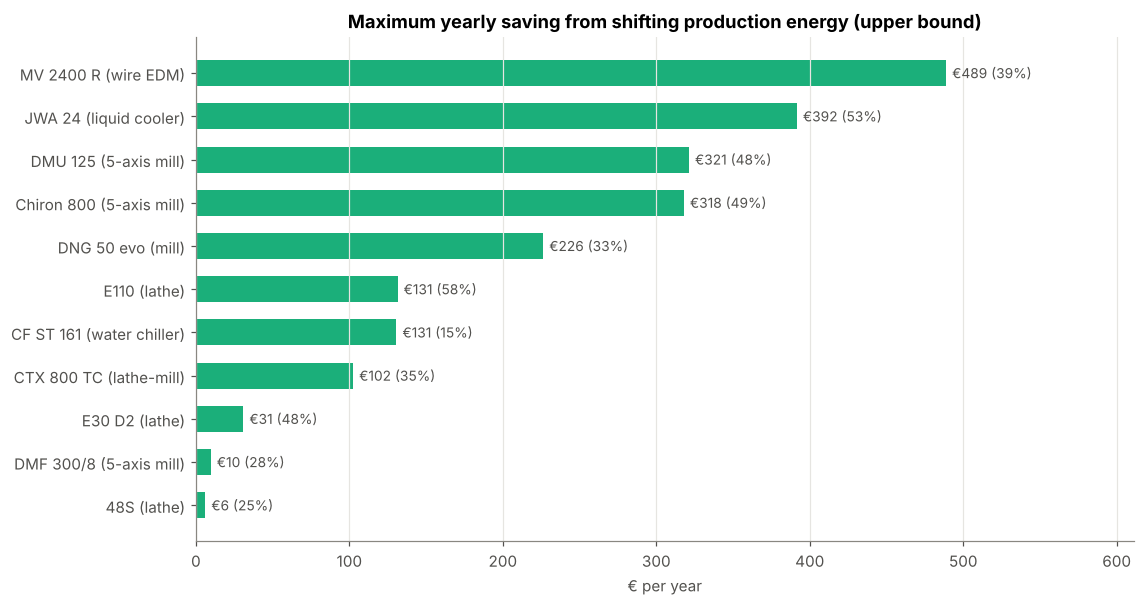

In [13]:
bm = bound.drop(index="TOTAL").sort_values("max_saving_eur")
bm = bm[bm["max_saving_eur"] > 1]
fig, ax = plt.subplots(figsize=(11, 0.45 * len(bm) + 1))
ax.barh(bm.index, bm["max_saving_eur"], color=COLORS[2], height=0.6)
for y, (v, p) in enumerate(zip(bm["max_saving_eur"], bm["max_saving_%_of_production"])):
    ax.annotate(f"{euro(v)} ({p:.0f}%)", xy=(v, y), xytext=(4, 0), textcoords="offset points",
                va="center", color="#52514e", fontsize=9)
ax.set(title="Maximum yearly saving from shifting production energy (upper bound)", xlabel="€ per year",
       xlim=(0, bm["max_saving_eur"].max() * 1.25))
ax.grid(axis="y", visible=False)
save(fig, "W2_D2_shift_upper_bound")
plt.show()

**Interpretation**

Shifting the production energy could save at most €2,157 per year. That is 39% of the production energy cost, but only 20% of the total baseline of €10,573. And this is an upper bound, the real saving will be lower because of job order, workers and set-up times.

The standby of the DNG 50 evo alone (€3,721 per year) is already bigger than all possible shifting savings together. So the plant manager should look at standby first: it is probably easier to fix, it does not change how production is planned, and the saving is more certain. Load shifting is still interesting as a second step.

For notebook 04 I would focus on the wire EDM (€489), the JWA 24 liquid cooler (€392) and the two 5-axis mills DMU 125 (€321) and Chiron 800 (€318). Together they make about 70% of the shifting potential. The small lathes are not worth optimising.

---
## Key findings

1. The 11 workshop machines would cost about €10,600 per year at 15-minute wholesale prices (100 MWh). The workshop pays 105 €/MWh, slightly above the market average of 104 €/MWh, because its shift starts during the morning price peak (07:00 to 09:00).
2. Energy use is very concentrated: four machines (DNG 50 evo, JWA 24, MV 2400 R, CF ST 161) use about 82% of the energy, the DNG 50 evo alone 42%.
3. Almost half of the energy (48%, about €5,070 per year) is standby at night and on weekends, mainly from the DNG 50 evo (4.1 kW non-stop, €3,700 per year) and the JWA 24 cooler (€1,300 per year).
4. Shifting production energy within the same day could save at most about €2,160 per year (20% of the baseline). The best candidates are the wire EDM and the two 5-axis mills.
5. Reducing standby is the bigger and easier lever than load shifting, but the reason why these machines stay on (for example thermal stability) has to be checked with the operators first.

## Next step
The upper bound assumes we know all prices in advance. In reality, a production planner has to plan days ahead.
notebook 03 builds a **price forecast** for 2–7 days ahead, so the plan in notebook 04 uses only information available at planning time.